In [1]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_ollama import ChatOllama
from langchain_core.messages import SystemMessage, HumanMessage


In [2]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description="What to cover")


In [3]:
class Plan(BaseModel):
    blog_title: str
    task : list[Task]

In [4]:
class State(TypedDict):
    topic : str
    plan : Plan
    # reducer: result from worker get Concatened automatically
    section: Annotated[List[str], operator.add]
    final: str

In [5]:
# Model
llm = ChatOllama(model="qwen3:1.7b")

In [6]:
def orchestrator(state: State) -> dict:

    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 section on the following topic."
                )
            ),
            HumanMessage(content=f'Topic: {state['topic']}'),
        ]
    )
    return {"plan": plan}

In [7]:
def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state['topic'], "plan": state['plan']})
            for task in state['plan'].task]

In [8]:
def worker(payload: dict) -> dict:
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]
    blog_title = plan.blog_title  
    
    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown Section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()
    
    return {"section": [section_md]}


In [9]:
def reducer(state: State) -> dict:
    title = state["plan"].blog_title
    body = "\n\n".join(state["section"])

    final_md = f"# {title}\n\n{body}\n"

    return {"final": final_md}

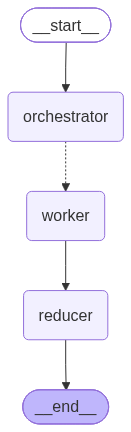

In [10]:
g = StateGraph(State)

g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ['worker'])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()

app


In [11]:
out = app.invoke({'topic': "write a blog on self Attention", "section": []})

In [12]:
out

{'topic': 'write a blog on self Attention',
 'plan': Plan(blog_title='Understanding Self-Attention in AI: A Comprehensive Guide', task=[Task(id=1, title='Introduction to Self-Attention', brief='Define self-attention and its role in AI models. Explain how it enables models to process complex data.'), Task(id=2, title='What is Self-Attention?', brief='Provide a clear explanation of self-attention, including its mechanism and how it differs from regular attention.'), Task(id=3, title='Importance of Self-Attention', brief='Discuss the significance of self-attention in enhancing AI performance, such as in NLP and computer vision.'), Task(id=4, title='Applications of Self-Attention', brief='Highlight real-world applications, like in transformers and other AI models.'), Task(id=5, title='Challenges and Limitations', brief='Address the challenges, such as computational cost and ethical concerns.'), Task(id=6, title='Future Trends and Innovations', brief='Explore upcoming developments in self-a

In [13]:
from pathlib import Path

output_path = Path.cwd() / "self_attention_blog.md"

output_path.write_text(out["final"], encoding="utf-8")

print("File saved at:", output_path.resolve())

File saved at: C:\Users\Khitish Panda\Desktop\AI Agent Plans, Researches & Writes Blogs Automatically using LangGraph\self_attention_blog.md
